# ComplaintRouter — Exploratory Data Analysis

This notebook explores the cleaned CFPB consumer complaint data used for
ComplaintRouter (`data/processed/complaint_router_modeling_data.csv`, built by
`01_data_cleaning.ipynb`). The analysis examines product class balance,
complaint narrative length, how many narratives were received over time,
frequent and discriminative terms across product categories, and company
responses, including the monetary relief label used for the second
prediction task.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.feature_selection import chi2

In [2]:
data_path = Path("../data/processed/complaint_router_modeling_data.csv")

figures_dir = Path("../figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# Short display labels for plots and wide tables
SHORT_LABELS = {
    "Checking or savings account": "Checking/Savings",
    "Credit card": "Credit Card",
    "Credit reporting or other personal consumer reports": "Credit Reporting",
    "Debt collection": "Debt Collection",
    "Debt or credit management": "Debt/Credit Mgmt",
    "Money transfer, virtual currency, or money service": "Money Transfer",
    "Mortgage": "Mortgage",
    "Payday loan, title loan, personal loan, or advance loan": "Payday/Personal Loan",
    "Prepaid card": "Prepaid Card",
    "Student loan": "Student Loan",
    "Vehicle loan or lease": "Vehicle Loan",
}

BAR_COLOR = "#2a78d6"
CONTEXT_COLOR = "#b4b2ab"

## 1. Dataset Overview

Each row is one unique complaint narrative. `clean_narrative` is the
cleaned text used as model input, `Product` is the label for the main
classification task, and `monetary_relief` is the label for the relief task.

In [3]:
df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print("Number of product classes:", df["Product"].nunique())
print("Date received range:", df["Date received"].min(), "to", df["Date received"].max())
print("Empty clean narratives:", (df["clean_narrative"].fillna("").str.strip() == "").sum())

df.head()

Dataset shape: (162500, 13)
Number of product classes: 11
Date received range: 2023-08-01 to 2026-07-27
Empty clean narratives: 0


,Complaint ID,Date received,Product,Sub-product,Issue,Sub-issue,Company,Company response to consumer,Timely response?,Consumer complaint narrative,clean_narrative,monetary_relief,split
0,15674347,2025-09-02,Debt collection,I do not know,False statements or representation,Attempted to collect wrong amount,NCB Management Services Inc.,Closed with explanation,Yes,ssue : Failure to provide proper debt validati...,ssue : failure to provide proper debt validati...,0.0,test
1,9002344,2024-05-14,Credit reporting or other personal consumer re...,Credit reporting,Improper use of your report,Reporting company used your report improperly,"EQUIFAX, INC.",Closed with non-monetary relief,Yes,"Delinquent, derogatory, and collection account...","delinquent, derogatory, and collection account...",0.0,test
2,20081098,2026-03-09,Credit card,General-purpose credit card or charge card,Problem with a purchase shown on your statement,Credit card company isn't resolving a dispute ...,SYNCHRONY FINANCIAL,Closed with explanation,Yes,In XXXX and XX/XX/XXXX2025 I financed an AirSc...,in and 2025 i financed an airsculpt procedure ...,0.0,train
3,10746790,2024-11-11,Checking or savings account,Checking account,Problem caused by your funds being low,Overdrafts and overdraft fees,NAVY FEDERAL CREDIT UNION,Closed with explanation,Yes,Overly charging for overdraft fees when i oppe...,overly charging for overdraft fees when i oppe...,0.0,train
4,13028279,2025-04-16,"Money transfer, virtual currency, or money ser...",Mobile or digital wallet,Fraud or scam,NaN,"Block, Inc.",Closed with explanation,Yes,I was sent an invitation to join Cash App from...,i was sent an invitation to join cash app from...,0.0,train


In [4]:
df.isna().sum().to_frame("Missing Values")

,Missing Values
Complaint ID,0
Date received,0
Product,0
Sub-product,0
Issue,0
Sub-issue,28053
Company,0
Company response to consumer,0
Timely response?,0
Consumer complaint narrative,0


### Train/Test Split

The cleaning notebook assigns every complaint to a fixed `split` (80% train,
20% test, stratified on Product, seed 42). All model notebooks use this
column, so every model is evaluated on exactly the same test complaints.

In [5]:
split_counts = pd.crosstab(
    df["Product"],
    df["split"],
    margins=True,
    margins_name="Total"
)[["train", "test", "Total"]]

split_counts["Test Share (%)"] = (
    split_counts["test"] / split_counts["Total"] * 100
).round(1)

split_counts

split,train,test,Total,Test Share (%)
Product,,,,
Checking or savings account,16000,4000,20000,20.0
Credit card,16000,4000,20000,20.0
Credit reporting or other personal consumer reports,28000,7000,35000,20.0
Debt collection,20000,5000,25000,20.0
Debt or credit management,4000,1000,5000,20.0
"Money transfer, virtual currency, or money service",12000,3000,15000,20.0
Mortgage,8000,2000,10000,20.0
"Payday loan, title loan, personal loan, or advance loan",6000,1500,7500,20.0
Prepaid card,4000,1000,5000,20.0


### Overview Findings

The modeling dataset contains **162,500** complaints across 11 product
categories, received between **August 1, 2023** and **July 27, 2026**. No
cleaned narrative is empty. The split assigns **130,000** complaints to
training and **32,500** to testing, and every product keeps a test share of
exactly 20%. The only missing values are `Sub-issue` (not used for
modeling) and `monetary_relief` for the 1,907 untimely / in-progress
complaints.

## 2. Product Class Distribution

We first examine the number of complaints represented by each financial
product category in the modeling dataset.

In [6]:
product_counts = df["Product"].value_counts()

product_table = pd.DataFrame({
    "Complaints": product_counts,
    "Share (%)": (product_counts / len(df) * 100).round(2),
})

product_table

,Complaints,Share (%)
Product,,
Credit reporting or other personal consumer reports,35000,21.54
Debt collection,25000,15.38
Credit card,20000,12.31
Checking or savings account,20000,12.31
"Money transfer, virtual currency, or money service",15000,9.23
Vehicle loan or lease,10000,6.15
Student loan,10000,6.15
Mortgage,10000,6.15
"Payday loan, title loan, personal loan, or advance loan",7500,4.62


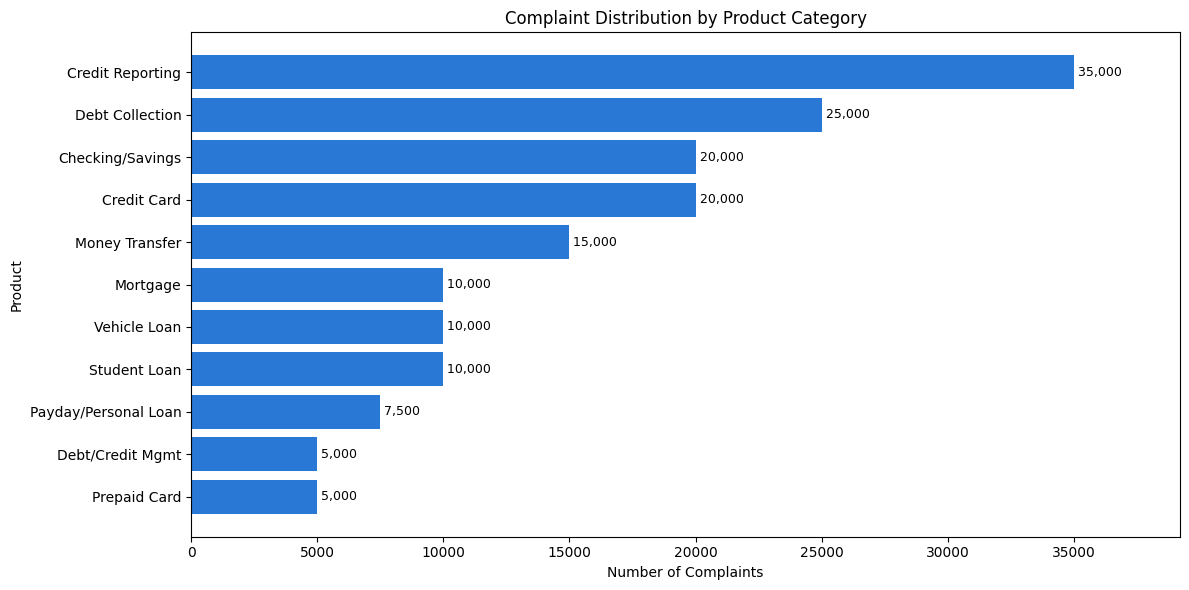

In [7]:
plot_counts = product_counts.sort_values()

fig, ax = plt.subplots(figsize=(12, 6))

ax.barh(
    [SHORT_LABELS[product] for product in plot_counts.index],
    plot_counts.values,
    color=BAR_COLOR
)

for position, value in enumerate(plot_counts.values):
    ax.text(value, position, f" {value:,}", va="center", fontsize=9)

ax.set_title("Complaint Distribution by Product Category")
ax.set_xlabel("Number of Complaints")
ax.set_ylabel("Product")
ax.set_xlim(0, plot_counts.max() * 1.12)
plt.tight_layout()

plt.savefig(
    figures_dir / "product_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Class Distribution Findings

The modeling dataset contains all 11 product categories but uses capped
sampling to reduce the dominance of the largest classes. Credit reporting
remains the largest category (**35,000** complaints, **21.5%**), while
prepaid cards and debt or credit management are the smallest (**5,000**
each, 3.1%). The largest class is still **7 times** the size of the
smallest, so macro-F1 (which weights every class equally) is used as the
headline metric.

## 3. Complaint Narrative Length

Length is measured as the word count of the raw consumer narrative.

In [8]:
df["narrative_word_count"] = (
    df["Consumer complaint narrative"]
    .astype(str)
    .str.split()
    .str.len()
)

print(df["narrative_word_count"].describe().round(1))

count    162500.0
mean        218.5
std         249.6
min           3.0
25%          82.0
50%         156.0
75%         274.0
max        5939.0
Name: narrative_word_count, dtype: float64


In [9]:
length_by_product = (
    df.groupby("Product")["narrative_word_count"]
    .agg(["mean", "median", "min", "max"])
    .round(1)
    .sort_values("median", ascending=False)
)

length_by_product

,mean,median,min,max
Product,,,,
Mortgage,302.6,220.0,6,5651
Vehicle loan or lease,249.0,186.0,5,5862
Credit card,226.6,176.0,4,5900
Student loan,221.8,167.0,7,4994
Checking or savings account,219.5,162.0,4,4449
Credit reporting or other personal consumer reports,230.6,157.0,3,5878
"Payday loan, title loan, personal loan, or advance loan",206.1,155.0,3,5939
Debt collection,189.5,134.0,3,5019
Prepaid card,182.4,134.0,4,3619


99th percentile: 1,135 words
Narratives above the 99th percentile (not shown): 1,623


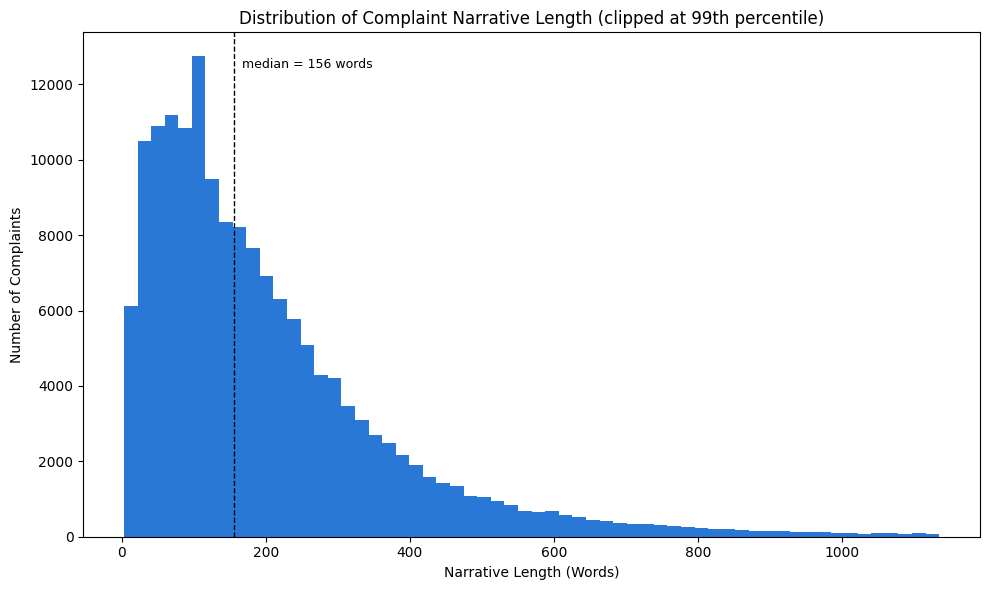

In [10]:
clip_value = df["narrative_word_count"].quantile(0.99)
median_length = df["narrative_word_count"].median()

print(f"99th percentile: {clip_value:,.0f} words")
print(f"Narratives above the 99th percentile (not shown): {(df['narrative_word_count'] > clip_value).sum():,}")

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    df.loc[df["narrative_word_count"] <= clip_value, "narrative_word_count"],
    bins=60,
    color=BAR_COLOR
)

ax.axvline(median_length, color="black", linestyle="--", linewidth=1)
ax.text(median_length, ax.get_ylim()[1] * 0.95, f"  median = {median_length:.0f} words", va="top", fontsize=9)

ax.set_title("Distribution of Complaint Narrative Length (clipped at 99th percentile)")
ax.set_xlabel("Narrative Length (Words)")
ax.set_ylabel("Number of Complaints")
plt.tight_layout()

plt.savefig(
    figures_dir / "narrative_length_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Narrative Length Findings

Complaint narratives are right-skewed, with a median length of **156** words
and a mean of approximately **219** words. 99% of complaints contain at most
**1,135** words, although a small number of much longer narratives (up to
5,939 words) create a long right tail. Narrative length also varies across
product categories: **mortgage** complaints have the highest median length
(220 words), while **debt or credit management** (110) and **money
transfer** (110) complaints are the shortest. The small spike just above
100 words comes largely from a templated complaint campaign (see Section 5).

In [11]:
# The raw narrative is only needed for word counts; drop it to free memory
df = df.drop(columns=["Consumer complaint narrative"])

## 4. Narratives Received Over Time

This section counts complaints in the modeling sample by the month they were
received. Because the sample is capped per product, the absolute counts are
smaller than in the full CFPB database, but the shape over time is still
informative.

The data comes from the CFPB bulk file archived on August 15, 2026, one day
after the CFPB stopped publishing new consumer narratives (August 14, 2026).
Narratives are published with a lag after a complaint is received, so the
latest narrative in the data was received on July 27, 2026, and the last
months before the cutoff are incomplete.

In [12]:
dates_received = pd.to_datetime(df["Date received"])

monthly_counts = dates_received.dt.to_period("M").value_counts().sort_index()
monthly_counts.index = monthly_counts.index.to_timestamp()

print("Months covered:", len(monthly_counts))
print("\nLast 12 months:")
print(monthly_counts.rename(index=lambda month: month.strftime("%Y-%m")).tail(12).to_string())

Months covered: 36

Last 12 months:
Date received
2025-08    6056
2025-09    5577
2025-10    5093
2025-11    5527
2025-12    4634
2026-01    4533
2026-02    2350
2026-03    4108
2026-04    4329
2026-05    3499
2026-06    2043
2026-07     537


In [13]:
year_counts = dates_received.dt.year.value_counts().sort_index()

year_counts.rename_axis("Year Received").to_frame("Complaints")

,Complaints
Year Received,
2023,15896
2024,50088
2025,75117
2026,21399


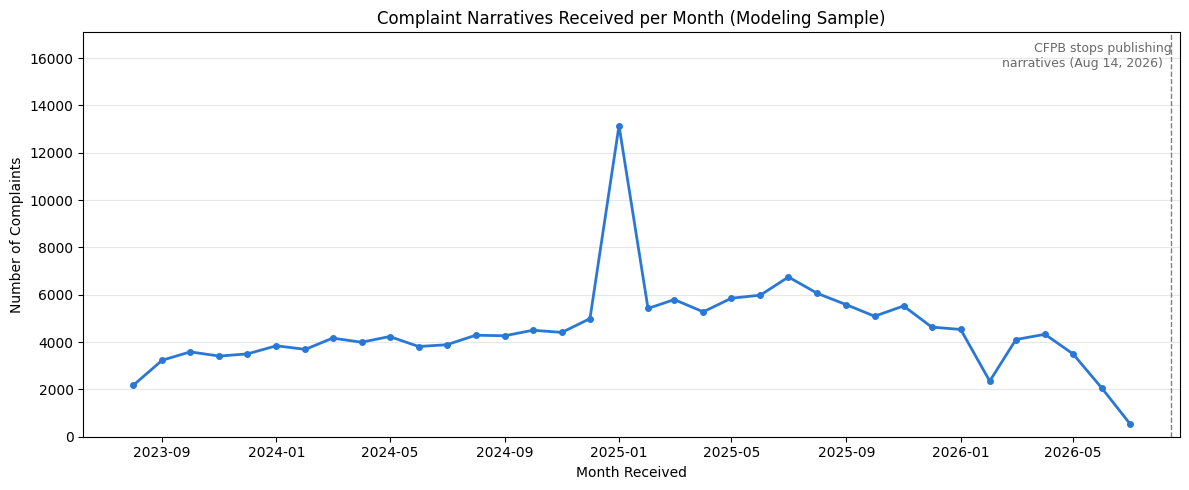

In [14]:
narrative_cutoff = pd.Timestamp("2026-08-14")

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    monthly_counts.index,
    monthly_counts.values,
    color=BAR_COLOR,
    linewidth=2,
    marker="o",
    markersize=4
)

ax.set_ylim(0, monthly_counts.max() * 1.3)
ax.axvline(narrative_cutoff, color="gray", linestyle="--", linewidth=1)
ax.text(
    narrative_cutoff,
    monthly_counts.max() * 1.27,
    "CFPB stops publishing\nnarratives (Aug 14, 2026)  ",
    ha="right",
    va="top",
    fontsize=9,
    color="dimgray"
)

ax.set_title("Complaint Narratives Received per Month (Modeling Sample)")
ax.set_xlabel("Month Received")
ax.set_ylabel("Number of Complaints")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_dir / "narratives_per_month.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Narratives Over Time Findings

- Monthly volume in the sample grows from about **3,200–5,000** complaints
  per month (late 2023–2024) to **4,600–6,800** in 2025.
- **January 2025 is a large outlier (13,147 complaints).** Most of the extra
  volume is money transfer complaints against Cash App (Block, Inc.) and
  Zelle (Early Warning Services) that follow the same template text (a
  coordinated complaint campaign), plus a surge of checking/savings and
  credit reporting complaints.
- **2026 drops sharply:** 2,350 narratives in February, 2,043 in June, and
  only **537** in July 2026. The July figure is low because narratives are
  published with a lag and publication stopped on August 14, 2026; the
  latest narrative in the data was received on July 27, 2026.
- **The product mix changes over time.** Credit reporting narratives almost
  disappear in 2026 (only **103 of 35,000** credit reporting complaints are
  from 2026, compared with 17,660 from 2025), while the other products
  continue at their usual rate. The date is not a model feature, but year
  tokens such as "2026" in the text could act as a weak "not credit
  reporting" signal.

Because the train/test split is random rather than by date, both splits
contain complaints from every period; a model deployed on future complaints
could face drift that this evaluation does not measure.

## 5. Frequent Terms by Product

Term statistics are computed on the **training split only**, so the test set
has no influence on any exploration that could guide modeling decisions.

### Mean TF-IDF Terms

The first table repeats the original analysis: the 10 terms with the
highest average TF-IDF weight within each product (5,000 unigrams).

In [15]:
train_df = df[df["split"] == "train"].reset_index(drop=True)

print(f"Training narratives: {len(train_df):,}")

vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    min_df=5
)

tfidf_matrix = vectorizer.fit_transform(
    train_df["clean_narrative"]
)

print("TF-IDF matrix shape:", tfidf_matrix.shape)

Training narratives: 130,000


TF-IDF matrix shape: (130000, 5000)


In [16]:
feature_names = np.array(vectorizer.get_feature_names_out())

top_terms_by_product = {}

for product in SHORT_LABELS:

    product_indices = (train_df["Product"] == product).to_numpy()

    mean_scores = np.asarray(
        tfidf_matrix[product_indices].mean(axis=0)
    ).ravel()

    top_indices = mean_scores.argsort()[-10:][::-1]

    top_terms_by_product[SHORT_LABELS[product]] = feature_names[top_indices]

top_terms_df = pd.DataFrame.from_dict(
    top_terms_by_product,
    orient="index"
)

top_terms_df.columns = [
    f"Term {i}" for i in range(1, 11)
]

# Free the TF-IDF matrix before building the larger bigram matrix
del tfidf_matrix

top_terms_df

,Term 1,Term 2,Term 3,Term 4,Term 5,Term 6,Term 7,Term 8,Term 9,Term 10
Checking/Savings,account,bank,funds,money,dollaramount,check,transactions,chase,deposit,told
Credit Card,card,credit,account,dollaramount,payment,bank,capital,charge,balance,charges
Credit Reporting,credit,report,reporting,information,account,consumer,accounts,15,inquiries,fcra
Debt Collection,debt,credit,collection,account,report,reporting,validation,information,company,original
Debt/Credit Mgmt,credit,debt,account,dollaramount,company,paid,report,settlement,payments,fees
Money Transfer,app,cash,account,zelle,money,funds,transfer,paypal,unfair,resolution
Mortgage,mortgage,loan,payment,escrow,insurance,dollaramount,home,payments,property,company
Payday/Personal Loan,loan,dollaramount,payment,payments,account,company,pay,credit,affirm,paid
Prepaid Card,card,gift,use,dollaramount,cards,money,tried,amex,account,express
Student Loan,loan,loans,mohela,student,payment,payments,forbearance,nelnet,dollaramount,plan


### Discriminative Terms (Chi-Squared)

Mean TF-IDF mostly surfaces words that are common in *every* complaint, such
as "credit", "account", and "bank", so the lists overlap heavily and say
little about what separates one product from another.

A chi-squared (χ²) test measures how strongly the presence of a term depends
on whether a complaint belongs to a given product (one product vs. all
others). Terms with the highest χ² scores are the ones whose usage differs
most between that product and the rest. Because χ² also rewards terms that
are unusually *rare* in a class, only terms that appear more often inside
the product than outside it are kept. Unigrams and bigrams are included,
using binary presence (does the narrative contain the term?).

In [17]:
count_vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=5,
    binary=True,
    dtype=np.float32
)

X_counts = count_vectorizer.fit_transform(train_df["clean_narrative"])
count_features = count_vectorizer.get_feature_names_out()

print("Binary term matrix shape:", X_counts.shape)

Binary term matrix shape: (130000, 323884)


In [18]:
y_train = train_df["Product"].to_numpy()
products = list(SHORT_LABELS)

# Number of training narratives in each product that contain each term (terms x products)
class_indicator = (y_train[:, None] == np.array(products)[None, :]).astype(np.float32)
docs_with_term = np.asarray(X_counts.T @ class_indicator)
class_sizes = class_indicator.sum(axis=0)
total_docs_with_term = docs_with_term.sum(axis=1)

chi2_terms_by_product = {}

for j, product in enumerate(products):
    scores, _ = chi2(X_counts, y_train == product)

    rate_in_product = docs_with_term[:, j] / class_sizes[j]
    rate_elsewhere = (total_docs_with_term - docs_with_term[:, j]) / (len(y_train) - class_sizes[j])

    # Keep only terms that are over-represented in this product
    scores = np.where(rate_in_product > rate_elsewhere, np.nan_to_num(scores), 0.0)

    top_indices = scores.argsort()[-10:][::-1]
    chi2_terms_by_product[SHORT_LABELS[product]] = count_features[top_indices]

chi2_terms_df = pd.DataFrame.from_dict(
    chi2_terms_by_product,
    orient="index"
)

chi2_terms_df.columns = [
    f"Term {i}" for i in range(1, 11)
]

chi2_terms_df

,Term 1,Term 2,Term 3,Term 4,Term 5,Term 6,Term 7,Term 8,Term 9,Term 10
Checking/Savings,checking,bank,checking account,deposit,funds,deposited,branch,overdraft,debit card,debit
Credit Card,credit card,card,synchrony,citi,synchrony bank,card account,card company,rewards,charge,merchant
Credit Reporting,credit report,report,fcra,reporting,credit reporting,reporting act,inquiries,inaccurate,fair credit,15
Debt Collection,debt,collection,debt collection,validation,collect,fdcpa,collection practices,fair debt,practices act,alleged debt
Debt/Credit Mgmt,debt relief,lexington,lexington law,debt settlement,enrolled debt,national debt,freedom debt,credit repair,settlement program,settlements
Money Transfer,platform,vulnerable,cash app,unprotected,fraud platform,platform leaving,vulnerable unprotected,account vulnerable,service unfair,prevent address
Mortgage,mortgage,escrow,foreclosure,property,mortgage company,mortgage payment,modification,home,escrow account,servicing
Payday/Personal Loan,loan,affirm,solar,personal loan,loan dollaramount,installment loan,took loan,dollaramount loan,title loan,main financial
Prepaid Card,gift,gift card,prepaid,gift cards,express gift,vanilla,amex gift,card,amex,prepaid card
Student Loan,student,mohela,loans,student loan,student loans,forbearance,federal student,education,repayment,forgiveness


In [19]:
# Free the large term matrix before continuing
del X_counts, class_indicator, docs_with_term, count_vectorizer, train_df

### Frequent Terms Findings

- **Mean TF-IDF repeats generic words.** "credit", "account", "loan",
  "payment", and the amount placeholder "dollaramount" appear in the top 10
  of many products, so the lists overlap heavily and do not show what
  separates products.
- **The χ² lists are far more distinctive.** They surface product-specific
  phrases such as "checking account" and "overdraft", "credit report" and
  "fcra", "fdcpa" and "alleged debt", "escrow" and "foreclosure",
  "repossession" and "dealership", "gift card" and "vanilla", and
  "forbearance" and "forgiveness". Bigrams like "debt relief", "lexington
  law", and "debt settlement" make the small Debt/Credit Mgmt class easy to
  recognize.
- **Company and brand names are strong clues**, for example "synchrony" and
  "citi" for credit cards, "mohela" for student loans, "affirm" for personal
  loans, "credit acceptance" for vehicle loans, and "cash app" for money
  transfers. This helps routing, but part of the signal comes from which
  company is mentioned rather than the problem described.
- **Template text dominates Money Transfer.** Its top χ² terms ("platform",
  "vulnerable", "unprotected", "service unfair", "prevent address") come from
  the January 2025 template campaign. About 2,300 of the 15,000 money
  transfer narratives contain this template, so near-identical copies sit
  in both train and test and will likely inflate Money Transfer scores.

## 6. Company Responses

The company's response to each complaint is used to build the monetary
relief label for the second prediction task.

In [20]:
response_counts = df["Company response to consumer"].value_counts()

response_table = pd.DataFrame({
    "Complaints": response_counts,
    "Share (%)": (response_counts / len(df) * 100).round(2),
})

response_table

,Complaints,Share (%)
Company response to consumer,,
Closed with explanation,125907,77.48
Closed with non-monetary relief,25480,15.68
Closed with monetary relief,9206,5.67
Untimely response,1880,1.16
In progress,27,0.02


### Monetary Relief Label

Following the project proposal, the relief task predicts **monetary relief
only**: `monetary_relief` is 1 for "Closed with monetary relief", 0 for any
other closed outcome (explanation or non-monetary relief), and missing for
"Untimely response" and "In progress" complaints, whose outcome is unknown.
Those complaints are excluded from the relief task rather than counted as
"no relief". The table below confirms the mapping.

In [21]:
relief_label_names = df["monetary_relief"].map({
    1.0: "1 (monetary relief)",
    0.0: "0 (other closed outcome)"
}).fillna("missing (excluded)").rename("Relief Label")

pd.crosstab(
    df["Company response to consumer"],
    relief_label_names
)

Relief Label,0 (other closed outcome),1 (monetary relief),missing (excluded)
Company response to consumer,,,
Closed with explanation,125907,0,0
Closed with monetary relief,0,9206,0
Closed with non-monetary relief,25480,0,0
In progress,0,0,27
Untimely response,0,0,1880


In [22]:
labeled = df[df["monetary_relief"].notna()].copy()

print(f"Complaints with a relief label: {len(labeled):,}")
print(f"Excluded (untimely / in progress): {df['monetary_relief'].isna().sum():,}")
print(f"Monetary relief prevalence: {labeled['monetary_relief'].mean():.2%}")

print("\nPrevalence by split:")
print(labeled.groupby("split")["monetary_relief"].mean().map("{:.2%}".format).to_string())

Complaints with a relief label: 160,593
Excluded (untimely / in progress): 1,907
Monetary relief prevalence: 5.73%

Prevalence by split:
split
test     5.64%
train    5.76%


## 7. Monetary Relief Rate by Product

This analysis compares the percentage of closed complaints that resulted in
monetary relief across product categories. The rate of *any* relief
(monetary or non-monetary) is shown alongside for context; both rates use
the same denominator (complaints with a known outcome).

In [23]:
relief_responses = [
    "Closed with monetary relief",
    "Closed with non-monetary relief"
]

labeled["any_relief"] = (
    labeled["Company response to consumer"]
    .isin(relief_responses)
)

relief_by_product = labeled.groupby("Product").agg(
    closed_complaints=("monetary_relief", "size"),
    monetary_relief_count=("monetary_relief", "sum"),
    monetary_relief_rate=("monetary_relief", "mean"),
    any_relief_rate=("any_relief", "mean"),
)

relief_by_product.columns = [
    "Closed Complaints",
    "Monetary Relief",
    "Monetary Relief Rate (%)",
    "Any Relief Rate (%)"
]

relief_by_product["Monetary Relief"] = relief_by_product["Monetary Relief"].astype(int)

rate_columns = ["Monetary Relief Rate (%)", "Any Relief Rate (%)"]
relief_by_product[rate_columns] = (relief_by_product[rate_columns] * 100).round(2)

relief_by_product = relief_by_product.sort_values(
    "Monetary Relief Rate (%)",
    ascending=False
)

relief_by_product

,Closed Complaints,Monetary Relief,Monetary Relief Rate (%),Any Relief Rate (%)
Product,,,,
Prepaid card,4994,1005,20.12,24.33
Credit card,19982,3647,18.25,30.30
Checking or savings account,19981,2615,13.09,19.00
"Money transfer, virtual currency, or money service",14961,777,5.19,8.62
Debt or credit management,4807,187,3.89,13.11
"Payday loan, title loan, personal loan, or advance loan",7410,284,3.83,7.14
Vehicle loan or lease,9939,274,2.76,8.28
Mortgage,9946,196,1.97,4.70
Student loan,8854,59,0.67,2.59


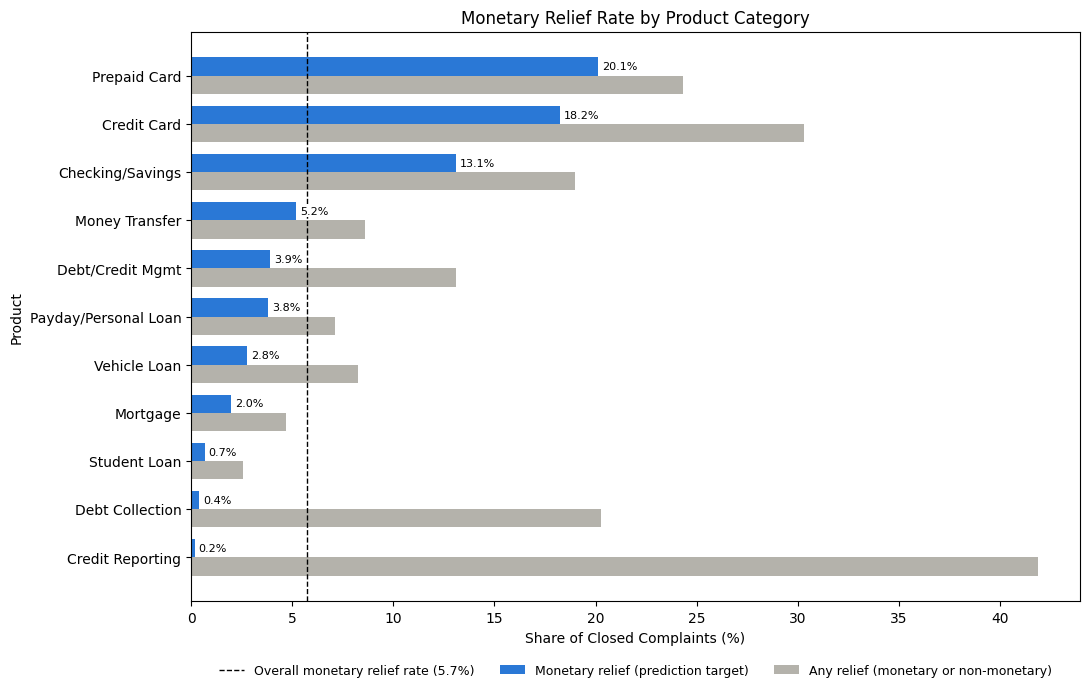

In [24]:
plot_data = relief_by_product.sort_values("Monetary Relief Rate (%)")
positions = np.arange(len(plot_data))
bar_height = 0.38
overall_monetary_rate = labeled["monetary_relief"].mean() * 100

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    positions + bar_height / 2,
    plot_data["Monetary Relief Rate (%)"],
    height=bar_height,
    color=BAR_COLOR,
    label="Monetary relief (prediction target)"
)

ax.barh(
    positions - bar_height / 2,
    plot_data["Any Relief Rate (%)"],
    height=bar_height,
    color=CONTEXT_COLOR,
    label="Any relief (monetary or non-monetary)"
)

for position, value in zip(positions, plot_data["Monetary Relief Rate (%)"]):
    ax.text(value + 0.2, position + bar_height / 2, f"{value:.1f}%", va="center", fontsize=8,
            bbox=dict(facecolor="white", edgecolor="none", pad=0.5), zorder=3)

ax.axvline(overall_monetary_rate, color="black", linestyle="--", linewidth=1,
           label=f"Overall monetary relief rate ({overall_monetary_rate:.1f}%)")

ax.set_yticks(positions)
ax.set_yticklabels([SHORT_LABELS[product] for product in plot_data.index])
ax.set_xlabel("Share of Closed Complaints (%)")
ax.set_ylabel("Product")
ax.set_title("Monetary Relief Rate by Product Category")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=3, frameon=False, fontsize=9)
plt.tight_layout()

plt.savefig(
    figures_dir / "relief_rate_by_product.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Relief Findings

Only **5.73%** of closed complaints (9,206 of 160,593) end with monetary
relief, and the rate is almost the same in train (5.76%) and test (5.64%).
The relief task is therefore highly imbalanced and should be judged with
ROC-AUC and PR-AUC rather than accuracy.

Monetary relief depends strongly on the product. It is most common for
**prepaid cards (20.1%)**, **credit cards (18.2%)**, and **checking/savings
accounts (13.1%)**, where refunds of fees or disputed charges are typical,
and rarest for **student loans (0.7%)**, **debt collection (0.4%)**, and
**credit reporting (0.2%)**. The product alone is therefore a strong
baseline predictor.

The any-relief rate tells a different story: **credit reporting** has the
highest any-relief rate (**41.9%**) and debt collection is at 20.3%, almost
entirely from non-monetary fixes such as corrections to a credit report.
This is why the monetary-only label used here (the proposal's definition)
gives a very different picture from the earlier any-relief analysis.

## Key Takeaways for Modeling

- **Class imbalance:** the capped sample still ranges from 35,000 (credit
  reporting) to 5,000 (prepaid card, debt/credit management) complaints, so
  macro-F1 is the headline metric.
- **Text length:** narratives are long and right-skewed (median 156 words),
  so TF-IDF with sublinear term frequency is a sensible representation.
- **Vocabulary:** discriminative bigrams and company names separate most
  products well. Overlapping banking products (checking/savings, credit
  card, prepaid card, money transfer) share many terms and are the likely
  sources of confusion.
- **Data quirks:** a January 2025 template campaign (about 2,300 near-identical
  money transfer narratives) and the near-absence of credit reporting
  narratives in 2026 could make test scores look better than they would on
  new complaints.
- **Monetary relief:** 5.73% positive, with rates ranging from 0.2% to 20.1%
  by product. Evaluate with ROC-AUC and PR-AUC, and compare text models
  with a product-only baseline.